# cfDNA ichorCNA genome-wide copy-number profiles (Figure 7d)

Reads tables from `../data/` and writes figures to `../output/`.
Source notebook: `../../NOTEBOOK_PROVENANCE.tsv`.

Two stacked genome-wide panels in the ichorCNA default style: Healthy samples
overlaid on top, Cancer samples overlaid on the bottom. Bin-level points and
segment medians are colored by ichorCNA event call (gain / neutral / loss).

Panels:
-`cfdna_ichorcna_genomewide`: Healthy vs Cancer genome-wide log2 copy-number ratio.


In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from notebook/, from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared savefig helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import savefig, set_paper_style  # repo fonts + pdf/png/svg/tsv
set_paper_style()
print("DATA:", DATA)
print("OUT :", OUT)


DATA: /home/jingz/leaf-1-figures/cfdna/data
OUT : /home/jingz/leaf-1-figures/cfdna/output


In [2]:
# ── Constants and helper functions (original ichorCNA layout, repo fonts) ──
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D

DEPTH_TABLE = DATA / "ichorcna_depth_for_plot.tsv"
SEGMENTS_TABLE = DATA / "ichorcna_segments_for_plot.tsv"
OUT_STEM = "cfdna_ichorcna_genomewide"

VALUE_COLUMN = "log2_TNratio_corrected"
CHR_ORDER = [str(i) for i in range(1, 23)]
GROUP_ORDER = ["Healthy", "Cancer"]
Y_LIMITS = (-2, 2)  # match ichorCNA genomeWide scaling

# Original ichorCNA-style event colors: decrease/loss, neutral, increase/gain.
EVENT_COLORS = {
    "HETD": "green", "HOMD": "green", "LOSS": "green", "DEL": "green",
    "NEUT": "blue",
    "GAIN": "red", "AMP": "red",
}
EVENT_ORDER = ["HETD", "HOMD", "LOSS", "DEL", "NEUT", "GAIN", "AMP"]
EVENT_LABELS = {"HETD": "Decrease/loss", "NEUT": "Neutral", "GAIN": "Increase/gain"}

POINT_SIZE = 3
POINT_ALPHA = 0.24
DRAW_SEGMENTS = True
SEGMENT_ALPHA = 0.70
SEGMENT_WIDTH = 0.75



def normalize_chr(value):
    return str(value).replace("chr", "")


def event_color(event):
    return EVENT_COLORS.get(str(event), "gray")


def event_sort_key(event):
    event = str(event)
    return EVENT_ORDER.index(event) if event in EVENT_ORDER else len(EVENT_ORDER)


def require_columns(df, columns, table_path):
    missing = [c for c in columns if c not in df.columns]
    if missing:
        raise ValueError(f"Missing columns in {table_path}: {missing}")


def load_depth_table(depth_table, value_column=VALUE_COLUMN):
    depth_table = Path(depth_table)
    if not depth_table.exists():
        raise FileNotFoundError(f"Missing depth table: {depth_table}")
    depth = pd.read_csv(depth_table, sep="\t", na_values=["NA"])
    require_columns(depth, ["sample_id", "group", "chr", "start", "end", "mid"], depth_table)
    if value_column in depth.columns:
        depth = depth.rename(columns={value_column: "value"})
    require_columns(depth, ["value"], depth_table)

    depth = depth.copy()
    depth["chr"] = depth["chr"].map(normalize_chr)
    depth = depth[depth["chr"].isin(CHR_ORDER)].copy()
    depth["chr_order"] = depth["chr"].map({c: i for i, c in enumerate(CHR_ORDER)})
    for col in ["start", "end", "mid", "value"]:
        depth[col] = pd.to_numeric(depth[col], errors="coerce")
    if "event" not in depth.columns:
        depth["event"] = "NEUT"
    if "copy.number" not in depth.columns:
        depth["copy.number"] = 2
    depth["event"] = depth["event"].fillna("NEUT").astype(str)
    depth = depth.dropna(subset=["start", "end", "mid", "value"]).copy()
    return depth.sort_values(["sample_id", "chr_order", "start"]).reset_index(drop=True)


def load_segment_table(segments_table):
    segments_table = Path(segments_table)
    cols = ["sample_id", "group", "chr", "chr_order", "start", "end", "median", "event", "copy.number"]
    if not segments_table.exists():
        return pd.DataFrame(columns=cols)
    segments = pd.read_csv(segments_table, sep="\t", na_values=["NA"])
    require_columns(segments, ["sample_id", "group", "chr", "start", "end", "median"], segments_table)

    segments = segments.copy()
    segments["chr"] = segments["chr"].map(normalize_chr)
    segments = segments[segments["chr"].isin(CHR_ORDER)].copy()
    segments["chr_order"] = segments["chr"].map({c: i for i, c in enumerate(CHR_ORDER)})
    for col in ["start", "end", "median"]:
        segments[col] = pd.to_numeric(segments[col], errors="coerce")
    if "event" not in segments.columns:
        segments["event"] = "NEUT"
    if "copy.number" not in segments.columns:
        segments["copy.number"] = pd.NA
    segments["event"] = segments["event"].fillna("NEUT").astype(str)
    segments = segments.dropna(subset=["start", "end", "median"]).copy()
    return segments.sort_values(["sample_id", "chr_order", "start"]).reset_index(drop=True)


def load_plot_tables(depth_table=DEPTH_TABLE, segments_table=SEGMENTS_TABLE):
    depth = load_depth_table(depth_table)
    segments = load_segment_table(segments_table)
    samples = depth[["sample_id", "group"]].drop_duplicates().to_dict("records")
    if not samples:
        raise ValueError(f"No samples found in {depth_table}")
    all_data = {}
    for s in samples:
        sid = s["sample_id"]
        all_data[sid] = {
            "group": s["group"],
            "depth": depth[depth["sample_id"] == sid].copy(),
            "segments": segments[segments["sample_id"] == sid].copy(),
        }
    return samples, all_data


def build_genome_axis(all_data):
    lengths = {c: 0 for c in CHR_ORDER}
    for item in all_data.values():
        for chrom, length in item["depth"].groupby("chr")["end"].max().items():
            lengths[chrom] = max(lengths[chrom], int(length))
    offsets, centers, boundaries, current = {}, {}, [], 0
    for chrom in CHR_ORDER:
        offsets[chrom] = current
        centers[chrom] = current + lengths[chrom] / 2
        boundaries.append(current)
        current += lengths[chrom]
    boundaries.append(current)
    return offsets, centers, boundaries


def add_genome_positions(all_data, offsets):
    for item in all_data.values():
        depth = item["depth"]
        depth["x"] = depth["chr"].map(offsets) + depth["mid"]
        seg = item["segments"]
        if not seg.empty:
            seg["x_start"] = seg["chr"].map(offsets) + seg["start"]
            seg["x_end"] = seg["chr"].map(offsets) + seg["end"]
    return all_data


def plot_event_points(ax, depth):
    for event in sorted(depth["event"].dropna().unique(), key=event_sort_key):
        sub = depth[depth["event"] == event]
        ax.scatter(sub["x"], sub["value"], s=POINT_SIZE, color=event_color(event),
                   alpha=POINT_ALPHA, linewidths=0, rasterized=True)


def plot_segments(ax, segments):
    for _, row in segments.iterrows():
        ax.hlines(row["median"], row["x_start"], row["x_end"],
                  color=event_color(row.get("event", "NEUT")), alpha=SEGMENT_ALPHA,
                  linewidth=SEGMENT_WIDTH, rasterized=True)


def add_event_legend(ax):
    handles = [
        Line2D([0], [0], marker="o", color="none", markerfacecolor=EVENT_COLORS["HETD"], markersize=5, label=EVENT_LABELS["HETD"]),
        Line2D([0], [0], marker="o", color="none", markerfacecolor=EVENT_COLORS["NEUT"], markersize=5, label=EVENT_LABELS["NEUT"]),
        Line2D([0], [0], marker="o", color="none", markerfacecolor=EVENT_COLORS["GAIN"], markersize=5, label=EVENT_LABELS["GAIN"]),
    ]
    ax.legend(handles=handles, loc="upper right", frameon=True)


def plot_group_panels(all_data, samples):
    """Two stacked genome-wide panels (Healthy / Cancer). Returns (fig, axes, plot_df)."""
    offsets, centers, boundaries = build_genome_axis(all_data)
    add_genome_positions(all_data, offsets)

    fig, axes = plt.subplots(len(GROUP_ORDER), 1, figsize=(20, 8), sharex=True,
                             gridspec_kw={"hspace": 0.10})
    group_counts = {g: sum(1 for s in samples if s["group"] == g) for g in GROUP_ORDER}

    for ax, group in zip(axes, GROUP_ORDER):
        for item in all_data.values():
            if item["group"] != group:
                continue
            plot_event_points(ax, item["depth"])
            if DRAW_SEGMENTS:
                plot_segments(ax, item["segments"])
        for boundary in boundaries:
            ax.axvline(boundary, color="black", linestyle="--", linewidth=0.4, alpha=0.55, zorder=0)
        ax.axhline(0, color="black", linewidth=0.5, alpha=0.7)
        ax.set_ylabel("Copy Number\n(log2 ratio)")
        ax.set_ylim(*Y_LIMITS)
        ax.yaxis.set_major_locator(ticker.FixedLocator([-2, -1, 0, 1, 2]))
        ax.tick_params(axis="both", which="both", length=4, pad=4)
        ax.text(0.01, 0.92, f"{group} (n={group_counts[group]})", transform=ax.transAxes,
                ha="left", va="top", fontweight="bold")

    add_event_legend(axes[0])
    axes[-1].xaxis.set_major_locator(ticker.FixedLocator([centers[c] for c in CHR_ORDER]))
    axes[-1].xaxis.set_major_formatter(ticker.FixedFormatter(CHR_ORDER))
    axes[-1].set_xlim(boundaries[0], boundaries[-1])

    fig.suptitle("ichorCNA genome-wide profiles", fontweight="bold", y=0.98)
    fig.subplots_adjust(left=0.06, right=0.99, top=0.92, bottom=0.10)

    plot_df = pd.concat(
        [item["depth"][["sample_id", "group", "chr", "mid", "value", "event", "copy.number"]]
         for item in all_data.values()],
        ignore_index=True,
    ).rename(columns={"value": VALUE_COLUMN})
    return fig, axes, plot_df

print("helpers loaded")


helpers loaded


In [3]:
samples, all_data = load_plot_tables(DEPTH_TABLE, SEGMENTS_TABLE)
print(f"Found {len(samples)} samples")
for s in samples:
    print(f"  {s['group']}: {s['sample_id']}")


Found 12 samples
  Healthy: HC1-cfDNA-WM_860466_1400_L001
  Healthy: HC10-cfDNA-WM_860469_1400_L001
  Healthy: HC12-cfDNA-WM_860470_1400_L001
  Healthy: HC13-cfDNA-WM_860471_1400_L001
  Healthy: HC7-cfDNA-WM_860467_1400_L001
  Healthy: HC9-cfDNA-WM_860468_1400_L001
  Cancer: KP100-cfDNA-WM_860475_1400_L001
  Cancer: KP106-cfDNA-WM_860476_1400_L001
  Cancer: KP122-cfDNA-WM_860477_1400_L001
  Cancer: KP94-cfDNA-WM_860472_1400_L001
  Cancer: KP95-cfDNA-WM_860473_1400_L001
  Cancer: KP99-cfDNA-WM_860474_1400_L001


saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_ichorcna_genomewide.pdf
saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_ichorcna_genomewide.png
saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_ichorcna_genomewide.svg
saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_ichorcna_genomewide.tsv


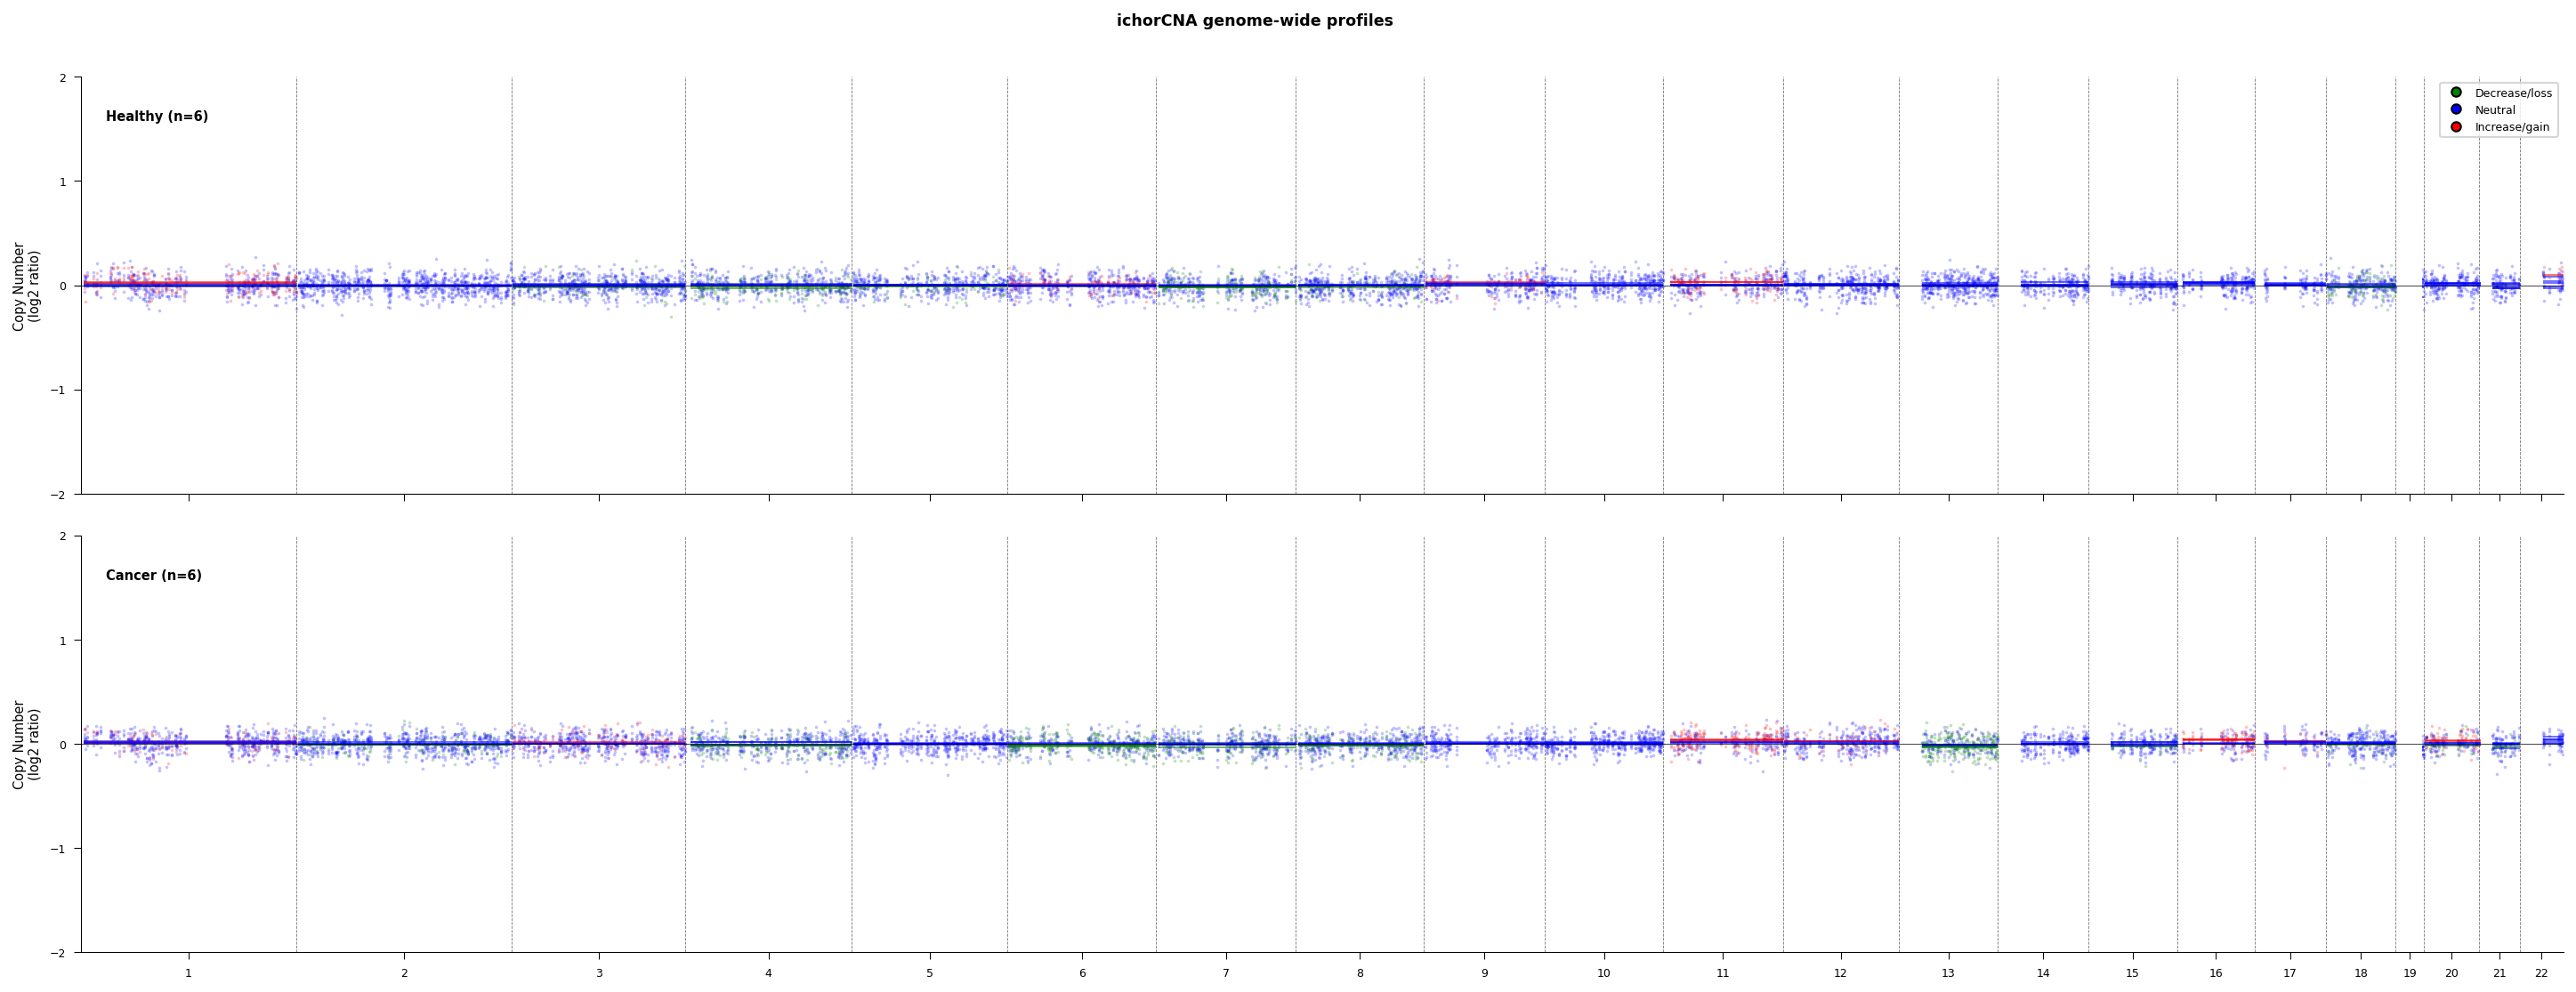

In [4]:
# ── Figure NN: Healthy vs Cancer genome-wide copy-number profiles ───────────
fig, axes, plot_df = plot_group_panels(all_data, samples)
savefig(fig, OUT, OUT_STEM, data=plot_df)
plt.show()
